# 07 · Execution costs: market vs limit orders on Binance spot and USDⓈ-M

Module **M2: order types and maker / taker** (Phase 1).

**Task.** Use the raw order-book snapshots stored by notebook 06 to price a **round trip**
(enter and exit a position) of 1k / 10k / 100k / 1M USDT, in three ways: market order in and
out (taker → taker), limit order in and out (maker → maker), and limit in, market out
(maker → taker: enter with a limit order, exit with a stop that becomes a market order). Split
the cost into **spread**, **impact** and **fee**.

**Markets.** Binance spot **BTC/USDT**, **ETH/USDT**, **PENGU/USDT** and the USDⓈ-M perpetual
**BTC/USDT:USDT**, exactly the books of notebook 06. Nothing is downloaded here.

**Order types in one paragraph.** A **market order** takes whatever is resting in the book,
best price first, until it is filled: it is executed at once but pays the spread and, if large,
"walks" to worse levels (**impact**). Its owner is the **taker** (takes liquidity) and pays the
taker fee. A **limit order** says "at this price or better": if it does not cross the spread it
rests in the book and waits; its owner is the **maker** (adds liquidity) and pays the maker fee,
but it may never be filled. A **stop order** waits until the price reaches a trigger and then
sends a market order, so its exit is a taker exit.

**Hypothesis (lab rule 1).** *I believe that for BTC and ETH, up to 100k USDT, the round-trip
cost is almost all fee, because their spread is one tick (a tiny fraction of a bp) and there is
enough depth at the best levels; so the choice of order type (maker vs taker fee) and of product
(spot vs perpetual fees) matters far more than the book. I believe that for PENGU, and for 1M
USDT orders, impact becomes the main cost, because the book is thin and a large order has to
walk many levels.*
*(Honest note: written after notebook 06, which measured the spread and the depth of these same
books, and after a first exploratory run of the per-leg costs in this notebook. The hypothesis is
therefore not blind.)*

**Scope.** One 45-minute window of one weekday (section 3). Nothing here generalizes to other
hours, days, or stressed markets.

## 1. Setup and parameters

Fees are **inputs**, not measured here. They are fractions of the notional (0.001 = 0.10% =
10 bps) and are charged on **every** leg.

| Product | Maker | Taker | Source and date |
|---|---|---|---|
| Spot, regular user (VIP 0) | 0.10% | 0.10% | secondary sources, 2026-11-19 |
| Spot, sensitivity: paying fees in BNB | 0.075% | 0.075% | the 25% BNB discount, same sources |
| USDⓈ-M futures, regular user | 0.02% | 0.05% | verified in Phase 0 |

Order sizes: **1,000 / 10,000 / 100,000 / 1,000,000 USDT** of notional per leg.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.order_book import default_markets, load_snapshots
from src.execution_costs import (SIZES_USDT, STATUS_EXHAUSTED, STATUS_FILLED, STATUS_TRUNCATED,
                                 cost_shares, market_order_legs, round_trips,
                                 summarize_round_trips)

SESSION_DIR = REPO_ROOT / "data" / "06_order_book" / "session"   # written by notebook 06
MARKETS = [m.label for m in default_markets("PENGU/USDT")]
SPOT_MARKETS = [m for m in MARKETS if m.startswith("spot")]
SIZES = SIZES_USDT                                                # USDT of notional per leg
CDMX = "America/Mexico_City"

# Fees as fractions of the notional (0.001 = 0.10%), per market. Sources: section 1 table.
SPOT_REGULAR = {"maker": 0.0010, "taker": 0.0010}   # secondary sources, read 2026-11-19
SPOT_BNB = {"maker": 0.00075, "taker": 0.00075}     # sensitivity: 25% discount paying in BNB
USDM_REGULAR = {"maker": 0.0002, "taker": 0.0005}   # verified in Phase 0
FEES = {m: (SPOT_REGULAR if m.startswith("spot") else USDM_REGULAR) for m in MARKETS}
FEES_BNB = {m: (SPOT_BNB if m.startswith("spot") else USDM_REGULAR) for m in MARKETS}

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.DataFrame(FEES).T.mul(100).add_suffix(" (%)")

,maker (%),taker (%)
spot BTC/USDT,0.10,0.10
spot ETH/USDT,0.10,0.10
spot PENGU/USDT,0.10,0.10
perp BTC/USDT:USDT,0.02,0.05


How to read it: one row per market, the maker and taker fee in percent of the notional that the
code will use. Spot is the same for maker and taker at the regular level; on the perpetual the
maker pays less than the taker.

## 2. Assumptions (read before the numbers)

1. **Impact from one snapshot is a LOWER BOUND of real slippage.** We walk a frozen photo of the
   book. A real order arrives after a delay (latency), some resting orders are cancelled before
   it reaches them, hidden orders (icebergs, RPI orders on USDⓈ-M) are not in the photo, and a
   limit order waits behind earlier orders at the same price (the **queue**). None of that is in
   here.
2. **The exit fee is charged on the same notional as the entry fee**: the price does not move
   between entry and exit, and the exit uses the **same snapshot** as the entry. So a round trip
   here is "the cost of being in and out immediately", without any market move.
3. **Order size is a notional in USDT on both sides**: a buy of N spends N USDT on the asks, a
   sell of N sells coins until it has received N USDT from the bids.
4. **Costs are measured against the mid** and expressed in **bps of the notional traded**
   (cost in USDT ÷ N × 10,000), so spread + impact + fee add up exactly. Per taker leg:
   *half spread* = distance from the mid to the best price, *impact* = distance from the best
   price to the average fill price, both times the coins traded.
5. **Limit (maker) legs: spread 0, fee only.** A buy limit at the best bid is filled (if it is)
   half a spread *below* the mid, so it actually **earns** half a spread versus the mid; we
   ignore that gain (conservative). With these books the gain is tiny for BTC and ETH and larger
   for PENGU.
6. **No fill probability and no adverse selection.** Nothing guarantees a limit order is filled,
   and the fills a limit order does get tend to come right before the price moves against it
   (adverse selection). Neither is measured here: the maker numbers are the cost **if** filled.
7. **Not fillable means no cost.** If the levels received do not add up to N, we do not
   extrapolate. Two cases (notebook 06, section 6): **"book truncated by the API"**: the side came
   back with the maximum number of levels (perp: 1000), so the book goes on beyond what we saw;
   **"book exhausted"**: the side came back with fewer levels than asked for, so we saw the whole
   visible book and it does not hold N.
8. **Funding of perpetuals is NOT included.** A perpetual position pays or receives funding every
   8 h; it is modeled in M8 with the real funding history of notebook 05. Here the perp round
   trip is instantaneous, so it pays none.
9. **The window is notebook 06's**: Thursday 2026-11-19, 22:00–22:45 UTC (16:00–16:45 Mexico
   City), collected with the collector's **old** behavior (after a retry it caught up by running
   rounds back to back; see notebook 06, Limitations). Do not generalize to other hours or to
   days of stress.

## 3. Load the snapshots, one market at a time

`load_snapshots(..., markets=[m])` reads only one market's rows from the Parquet file, so the
4 markets never sit in memory together (a spot market is a few million rows, one per price
level). For each market, `market_order_legs` (in `src/execution_costs.py`) walks every snapshot
with a market buy and a market sell of each size; only that small result is kept. Snapshots are
placed in time by **`local_receive_utc`**, the first moment we knew the book; we check that
ordering by it gives the same order as the request time.

In [2]:
legs_by_market, first_book, window_rows = [], {}, []
for market in MARKETS:
    levels = load_snapshots(SESSION_DIR, markets=[market])
    legs_by_market.append(market_order_legs(levels, SIZES))
    snaps = levels.groupby("local_request_utc", observed=True)["local_receive_utc"].first()
    first_request = snaps.sort_values().index[0]            # earliest snapshot by receive time
    first_book[market] = levels[levels["local_request_utc"] == first_request].copy()
    window_rows.append({
        "market": market, "price levels (rows)": len(levels), "snapshots": len(snaps),
        "first receive (UTC)": snaps.min(), "last receive (UTC)": snaps.max(),
        "receive order = request order": bool(snaps.sort_values().index.is_monotonic_increasing),
        "median latency (ms)": (snaps - snaps.index).dt.total_seconds().median() * 1000})
    del levels                                               # free memory before the next one
legs = pd.concat(legs_by_market, ignore_index=True)
window = pd.DataFrame(window_rows).set_index("market")
start, end = window["first receive (UTC)"].min(), window["last receive (UTC)"].max()
print(f"window: {start:%Y-%m-%d %H:%M:%S} → {end:%H:%M:%S} UTC  "
      f"({start.tz_convert(CDMX):%H:%M} → {end.tz_convert(CDMX):%H:%M} Mexico City, {start:%A})")
print(f"legs: {len(legs):,} rows = snapshots × 2 actions (buy, sell) × {len(SIZES)} sizes")
window

window: 2026-11-19 22:00:13 → 22:45:04 UTC  (16:00 → 16:45 Mexico City, Thursday)
legs: 8,640 rows = snapshots × 2 actions (buy, sell) × 4 sizes


,price levels (rows),snapshots,first receive (UTC),last receive (UTC),receive order = request order,median latency (ms)
market,,,,,,
spot BTC/USDT,2700000,270,2026-11-19 22:00:13.765+00:00,2026-11-19 22:45:03.377+00:00,True,221.0
spot ETH/USDT,2700000,270,2026-11-19 22:00:14.200+00:00,2026-11-19 22:45:03.612+00:00,True,220.0
spot PENGU/USDT,1445323,270,2026-11-19 22:00:14.606+00:00,2026-11-19 22:45:03.851+00:00,True,209.0
perp BTC/USDT:USDT,540000,270,2026-11-19 22:00:15.222+00:00,2026-11-19 22:45:04.092+00:00,True,203.0


How to read it: the first line is the window covered by the snapshots, by receive time, in UTC and
Mexico City time. The table has one row per market: how many price levels were read, how many
snapshots, the first and last receive time, whether sorting by receive time keeps the request
order (True = the two clocks never swap two snapshots, so either can be used to order; we use the
receive time to align with anything else), and the median time between request and receive.

## 4. One snapshot, walked by hand

The earliest snapshot of each market, with a market **buy** of each size. This is what the code
does 270 times per market.

In [3]:
first_legs = legs.merge(
    pd.DataFrame([{"market": m, "local_request_utc": b["local_request_utc"].iloc[0]}
                  for m, b in first_book.items()]), on=["market", "local_request_utc"])
example = first_legs[first_legs["action"] == "buy"].set_index(["market", "size_usdt"])[
    ["best_ask", "mid", "avg_price", "levels_used", "base_filled", "half_spread_bps",
     "impact_bps", "slippage_bps", "status"]].reindex(MARKETS, level=0)
formats = {"best_ask": "{:,.8g}", "mid": "{:,.8g}", "avg_price": "{:,.8g}",
           "levels_used": "{:,.0f}", "base_filled": "{:,.6g}", "half_spread_bps": "{:.4f}",
           "impact_bps": "{:.4f}", "slippage_bps": "{:.4f}"}
example.apply(lambda col: col.map(formats[col.name].format) if col.name in formats else col)

best_ask         mid     avg_price levels_used  base_filled half_spread_bps impact_bps slippage_bps  status
market             size_usdt                                                                                                             
spot BTC/USDT      1000.0     61,537.3  61,537.295      61,537.3           1    0.0162503          0.0008     0.0000       0.0008  filled
                   10000.0    61,537.3  61,537.295      61,537.3           1     0.162503          0.0008     0.0000       0.0008  filled
                   100000.0   61,537.3  61,537.295      61,537.3           1      1.62503          0.0008     0.0000       0.0008  filled
                   1000000.0  61,537.3  61,537.295    61,539.508          60      16.2497          0.0008     0.3588       0.3596  filled
spot ETH/USDT      1000.0     1,740.47   1,740.465      1,740.47           1     0.574557          0.0287     0.0000       0.0287  filled
                   10000.0    1,740.47   1,740.465      1,740.47           1      5.74557          0.0287     0.0000       0.0287  filled
                   100000.0   1,740.47   1,740.465      1,740.47           1      57.4557          0.0287     0.0000       0.0287  filled
                   1000000.0  1,740.47   1,740.465    1,740.9261          67      574.407          0.0287     2.6197       2.6484  filled
spot PENGU/USDT    1000.0     0.004544   0.0045435  0.0045445574           2      220,043          1.1002     1.2265       2.3267  filled
                   10000.0    0.004544   0.0045435  0.0045467012           5   2.1994e+06          1.0997     5.9409       7.0406  filled
                   100000.0   0.004544   0.0045435   0.004557331          27  2.19427e+07          1.0971    29.2518      30.3489  filled
                   1000000.0  0.004544   0.0045435  0.0058735701       1,456  1.70254e+08          0.8513  2263.6489    2264.5002  filled
perp BTC/USDT:USDT 1000.0     61,503.3   61,503.25      61,503.3           1    0.0162593          0.0081     0.0000       0.0081  filled
                   10000.0    61,503.3   61,503.25      61,503.3           1     0.162593          0.0081     0.0000       0.0081  filled
                   100000.0   61,503.3   61,503.25    61,504.762          29      1.62589          0.0081     0.2377       0.2459  filled
                   1000000.0  61,503.3   61,503.25    61,513.853          93      16.2565          0.0081     1.7155       1.7236  filled

How to read it: one row per market and order size (USDT). `best_ask` is the lowest sell price in
the book, `mid` the point halfway between the best bid and best ask, `avg_price` what the buy
paid on average (size ÷ coins received). `levels_used` is how many price levels the order ate;
`base_filled` the coins bought. Costs in bps of the notional: `half_spread_bps` (mid → best
ask), `impact_bps` (best ask → average price) and their sum `slippage_bps`. While the order fits
in the first level, impact is zero and the cost is just half the spread; once it needs more
levels, impact appears and grows with size. Very small non-zero impacts (around 1e-12) are
floating-point rounding, not cost.

## 5. Can the book fill the order? Truncated vs exhausted

For each market, action and size: in how many of the snapshots the visible book could fill the
order, was truncated by the API, or was exhausted.

In [4]:
status = (legs.groupby(["market", "action", "size_usdt"])["status"].value_counts()
          .unstack(fill_value=0)
          .reindex(columns=[STATUS_FILLED, STATUS_TRUNCATED, STATUS_EXHAUSTED], fill_value=0))
depth_used = legs.groupby(["market", "action", "size_usdt"]).agg(
    levels_returned_min=("n_levels", "min"), levels_asked=("requested_limit", "first"),
    levels_used_max=("levels_used", "max"),
    side_total_min_musdt=("total_quote", lambda x: x.min() / 1e6))
status.join(depth_used).reindex(MARKETS, level=0).round(3)

filled  book truncated by the API  book exhausted  levels_returned_min  levels_asked  levels_used_max  \
market             action size_usdt                                                                                                          
spot BTC/USDT      buy    1000.0        270                          0               0                 5000          5000               15   
                          10000.0       270                          0               0                 5000          5000               41   
                          100000.0      270                          0               0                 5000          5000              104   
                          1000000.0     270                          0               0                 5000          5000              210   
                   sell   1000.0        270                          0               0                 5000          5000               17   
                          10000.0       270                          0               0                 5000          5000               42   
                          100000.0      270                          0               0                 5000          5000               74   
                          1000000.0     270                          0               0                 5000          5000              143   
spot ETH/USDT      buy    1000.0        270                          0               0                 5000          5000                8   
                          10000.0       270                          0               0                 5000          5000               24   
                          100000.0      270                          0               0                 5000          5000               41   
                          1000000.0     270                          0               0                 5000          5000              121   
                   sell   1000.0        270                          0               0                 5000          5000                9   
                          10000.0       270                          0               0                 5000          5000               28   
                          100000.0      270                          0               0                 5000          5000               45   
                          1000000.0     270                          0               0                 5000          5000              117   
spot PENGU/USDT    buy    1000.0        270                          0               0                 5000          5000                5   
                          10000.0       270                          0               0                 5000          5000                8   
                          100000.0      270                          0               0                 5000          5000               46   
                          1000000.0     270                          0               0                 5000          5000             1467   
                   sell   1000.0        270                          0               0                  332          5000                4   
                          10000.0       270                          0               0                  332          5000                7   
                          100000.0      270                          0               0                  332          5000               31   
                          1000000.0       0                          0             270                  332          5000              373   
perp BTC/USDT:USDT buy    1000.0        270                          0               0                 1000          1000                1   
                          10000.0       270                          0               0                 1000          1000                1   
                          100000.0      270                  

How to read it: one row per market, action (`buy` walks the asks, `sell` the bids) and size. The
first three columns count snapshots: fillable, **truncated by the API** (the side came back with
all the levels asked for and still did not add up to the size: the book goes on, we cannot see
it), **exhausted** (the side came back with fewer levels than asked: that was the whole visible
book). `levels_returned_min` vs `levels_asked`: if the minimum returned is below what was asked,
that side of the book ended. `levels_used_max`: the deepest level any fill needed.
`side_total_min_musdt`: the smallest total on that side in any snapshot, in millions of USDT. A
row that is not fillable in every snapshot gets **no cost** in the rest of the notebook.

## 6. One leg: the cost of a market order

Median and p90 across snapshots, fillable snapshots only, in bps of the notional. The taker fee
is added in the last column to see one full taker leg.

In [5]:
filled_legs = legs[legs["status"] == STATUS_FILLED]
g = filled_legs.groupby(["market", "action", "size_usdt"])
one_leg = pd.DataFrame({
    "n fillable": g.size(),
    "half spread, median": g["half_spread_bps"].median(),
    "impact, median": g["impact_bps"].median(),
    "impact, p90": g["impact_bps"].quantile(0.9),
    "half spread + impact, median": g["slippage_bps"].median(),
    "half spread + impact, p90": g["slippage_bps"].quantile(0.9),
})
taker_fee_bps = pd.Series({m: FEES[m]["taker"] * 1e4 for m in MARKETS})
one_leg["taker fee"] = taker_fee_bps.reindex(one_leg.index.get_level_values("market")).values
one_leg["taker leg total, median"] = one_leg["half spread + impact, median"] + one_leg["taker fee"]
one_leg.reindex(MARKETS, level=0).round(4)

n fillable  half spread, median  impact, median  impact, p90  half spread + impact, median  half spread + impact, p90  \
market             action size_usdt                                                                                                                          
spot BTC/USDT      buy    1000.0            270               0.0008          0.0000       0.0000                        0.0008                     0.0008   
                          10000.0           270               0.0008          0.0000       0.3005                        0.0008                     0.3013   
                          100000.0          270               0.0008          0.1895       1.1843                        0.1903                     1.1851   
                          1000000.0         270               0.0008          1.5177       2.5917                        1.5185                     2.5926   
                   sell   1000.0            270               0.0008          0.0000       0.0000                        0.0008                     0.0008   
                          10000.0           270               0.0008          0.0000       0.0000                        0.0008                     0.0008   
                          100000.0          270               0.0008          0.0000       0.6493                        0.0008                     0.6501   
                          1000000.0         270               0.0008          1.0978       2.0307                        1.0986                     2.0315   
spot ETH/USDT      buy    1000.0            270               0.0285          0.0000       0.0000                        0.0285                     0.0287   
                          10000.0           270               0.0285          0.0000       0.4750                        0.0286                     0.5036   
                          100000.0          270               0.0285          0.6143       1.7558                        0.6428                     1.7842   
                          1000000.0         270               0.0285          3.4394       4.5695                        3.4679                     4.5979   
                   sell   1000.0            270               0.0285          0.0000       0.0000                        0.0286                     0.0287   
                          10000.0           270               0.0285          0.0000       0.4281                        0.0286                     0.4568   
                          100000.0          270               0.0285          0.1216       1.6721                        0.1502                     1.7004   
                          1000000.0         270               0.0285          2.7667       4.2214                        2.7952                     4.2497   
spot PENGU/USDT    buy    1000.0            270               1.0974          2.0974       3.7546                        3.1968                     4.8526   
                          10000.0           270               1.0968          7.1958       9.1278                        8.2887                    10.2277   
                          100000.0          270               1.0937         34.9560      38.8578                       36.0461                    39.9500   
                          1000000.0         270               0.8484       2270.0268    2307.1502                     2270.8767                  2307.9965   
                   sell   1000.0            270               1.0981          2.0086       3.7537                        3.1062                     4.8546   
                          10000.0           270               1.0985          6.0554       7.8055                        7.1560                     8.9082   
                          100000.0          270               1.1007         24.7110      29.4959                       25.8143                    30.6370   
perp BTC/USDT:USDT buy    1000.0            270               0.0081          0.0000   

How to read it: one row per market, action and size; every cost column in **bps of the notional**
(1 bp = 0.01%). `half spread` depends on the book's spread only, so it hardly changes with size;
`impact` is zero while the order fits in the best level and then grows with size. p90 is a bad
but not rare snapshot (10% of snapshots were worse). The last two columns put the taker fee next
to the book cost: whichever is larger dominates the cost of a market order. Rows missing here had
no fillable snapshot (see section 5).

## 7. Round trips: entry + exit

`round_trips` adds an entry leg and an exit leg on the same snapshot and notional:

- **taker → taker**: market in, market out. Pays both half spreads, both impacts and two taker fees.
- **maker → maker**: limit in, limit out. Two maker fees, nothing else (assumptions 5–6).
- **maker → taker**: limit in, market (stop) out. One maker fee, one taker fee, and the half
  spread + impact of the exit only. This depends on the **direction**: a *long* exits with a
  market **sell** (walks the bids), a *short* with a market **buy** (walks the asks).

For taker → taker and maker → maker, long and short use the same two legs, so they cost the same
(checked below), and only the long is shown.

In [6]:
rt = round_trips(legs, FEES)
key = ["market", "local_request_utc", "size_usdt"]
for combo in ("taker -> taker", "maker -> maker"):
    a = rt[(rt["combo"] == combo) & (rt["direction"] == "long")].set_index(key)["total_bps"]
    b = rt[(rt["combo"] == combo) & (rt["direction"] == "short")].set_index(key)["total_bps"]
    assert np.allclose(a, b.reindex(a.index), equal_nan=True), combo
summary = summarize_round_trips(rt)

VIEWS = {"taker → taker": ("taker -> taker", "long"), "maker → maker": ("maker -> maker", "long"),
         "maker → taker (long)": ("maker -> taker", "long"),
         "maker → taker (short)": ("maker -> taker", "short")}


def cost_cell(row, stat, unit):
    if row["n_fillable"] == 0:
        reason = STATUS_EXHAUSTED if row["n_exhausted"] else STATUS_TRUNCATED
        return f"not fillable ({reason})"
    value = row[f"{stat}_{unit}"]
    text = f"{value:,.2f}"
    if row["n_unfillable"]:   # some snapshots left out: biased low
        text += f" (only {row['n_fillable']}/{row['n_snapshots']} fillable)"
    return text


def round_trip_table(summary, unit):
    out = {}
    for label, (combo, direction) in VIEWS.items():
        part = summary.xs((combo, direction), level=("combo", "direction"))
        for stat in ("median", "p90"):
            out[(label, stat)] = part.apply(cost_cell, axis=1, stat=stat, unit=unit)
    table = pd.DataFrame(out)
    table.index = pd.MultiIndex.from_tuples(
        [(m, f"{s:,.0f}") for m, s in table.index], names=["market", "size (USDT)"])
    return table.reindex(MARKETS, level=0)


round_trip_table(summary, "bps")

taker → taker                                maker → maker                  maker → taker (long)  \
                                                       median                            p90        median    p90                         median   
market             size (USDT)                                                                                                                     
spot BTC/USDT      1,000                                20.00                          20.01         20.00  20.00                          20.00   
                   10,000                               20.00                          20.48         20.00  20.00                          20.00   
                   100,000                              20.54                          21.26         20.00  20.00                          20.00   
                   1,000,000                            22.75                          23.29         20.00  20.00                          21.10   
spot ETH/USDT      1,000                                20.06                          20.08         20.00  20.00                          20.03   
                   10,000                               20.06                          20.76         20.00  20.00                          20.03   
                   100,000                              21.23                          22.02         20.00  20.00                          20.15   
                   1,000,000                            26.32                          26.95         20.00  20.00                          22.80   
spot PENGU/USDT    1,000                                26.42                          27.96         20.00  20.00                          23.11   
                   10,000                               35.44                          37.49         20.00  20.00                          27.16   
                   100,000                              82.27                          87.45         20.00  20.00                          45.81   
                   1,000,000    not fillable (book exhausted)  not fillable (book exhausted)         20.00  20.00  not fillable (book exhausted)   
perp BTC/USDT:USDT 1,000                                10.02                          10.02          4.00   4.00                           7.01   
                   10,000                               10.02                          10.02          4.00   4.00                           7.01   
                   100,000                              10.02                          10.17          4.00   4.00                           7.01   
                   1,000,000                            11.25                          11.72          4.00   4.00                           7.47   

                                                              maker → taker (short)            
                                                          p90                median       p90  
market             size (USDT)                                                                 
spot BTC/USDT      1,000                                20.00                 20.00     20.00  
                   10,000                               20.00                 20.00     20.30  
                   100,000                              20.65                 20.19     21.19  
                   1,000,000                            22.03                 21.52     22.59  
spot ETH/USDT      1,000                                20.03                 20.03     20.03  
                   10,000                               20.46                 20.03     20.50  
                   100,000                              21.70                 20.64     21.78  
                   1,000,000                            24.25                 23.47     24.60  
spot PENGU/USDT    1,000                                24.85                 23.20     24.85  
                   10,000                               28.91                 28.29

How to read it: one row per market and size (USDT per leg). Each pair of columns is one way to
enter and exit; `median` is the typical snapshot and `p90` a bad-but-not-rare one, across the
fillable snapshots. Units: **bps of the notional** for the whole round trip (20 bps = 0.20% of
the position, paid once to get in and out). "not fillable (book exhausted)" means the visible book
could not fill the size in any snapshot, so no cost is reported. maker → maker is the same for
every size because it is only fees, and fees are a fixed share of the notional; the other two
grow with size only through impact. Careful with maker → maker at sizes the book cannot hold
(e.g. a 1M limit sell where the whole bid side is smaller): the number is the fee **if** someone
took the whole order, which this notebook does not check (assumption 6).

In [7]:
round_trip_table(summary, "usdt")

taker → taker                                maker → maker                     maker → taker (long)  \
                                                       median                            p90        median       p90                         median   
market             size (USDT)                                                                                                                        
spot BTC/USDT      1,000                                 2.00                           2.00          2.00      2.00                           2.00   
                   10,000                               20.00                          20.48         20.00     20.00                          20.00   
                   100,000                             205.36                         212.64        200.00    200.00                         200.01   
                   1,000,000                         2,274.81                       2,328.53      2,000.00  2,000.00                       2,109.86   
spot ETH/USDT      1,000                                 2.01                           2.01          2.00      2.00                           2.00   
                   10,000                               20.06                          20.76         20.00     20.00                          20.03   
                   100,000                             212.34                         220.20        200.00    200.00                         201.50   
                   1,000,000                         2,631.52                       2,694.62      2,000.00  2,000.00                       2,279.52   
spot PENGU/USDT    1,000                                 2.64                           2.80          2.00      2.00                           2.31   
                   10,000                               35.44                          37.49         20.00     20.00                          27.16   
                   100,000                             822.72                         874.51        200.00    200.00                         458.14   
                   1,000,000    not fillable (book exhausted)  not fillable (book exhausted)      2,000.00  2,000.00  not fillable (book exhausted)   
perp BTC/USDT:USDT 1,000                                 1.00                           1.00          0.40      0.40                           0.70   
                   10,000                               10.02                          10.02          4.00      4.00                           7.01   
                   100,000                             100.16                         101.70         40.00     40.00                          70.08   
                   1,000,000                         1,125.33                       1,172.29        400.00    400.00                         746.72   

                                                              maker → taker (short)              
                                                          p90                median         p90  
market             size (USDT)                                                                   
spot BTC/USDT      1,000                                 2.00                  2.00        2.00  
                   10,000                               20.00                 20.00       20.30  
                   100,000                             206.50                201.90      211.85  
                   1,000,000                         2,203.15              2,151.85    2,259.26  
spot ETH/USDT      1,000                                 2.00                  2.00        2.00  
                   10,000                               20.46                 20.03       20.50  
                   100,000                             217.00                206.43      217.84  
                   1,000,000                         2,424.97              2,346.79    2,459.79  
spot PENGU/USDT    1,000                                 2.49                  2.32        2.49  
  

How to read it: the same table in **USDT** for the whole round trip (cost in bps × size ÷ 10,000).
Within a market the USDT cost grows at least in proportion to size (10 times the size, at least
10 times the USDT), faster when impact kicks in.

## 8. BTC: spot vs perpetual

Same coin, same exchange, same window, two products with different books and different fees.
`spot − perp` above zero means the spot round trip costs more.

In [8]:
def btc_compare(summary, unit):
    spot = summary.xs("spot BTC/USDT", level="market")
    perp = summary.xs("perp BTC/USDT:USDT", level="market")
    out = {}
    for label, (combo, direction) in VIEWS.items():
        s = spot.xs((combo, direction), level=("combo", "direction"))[f"median_{unit}"]
        p = perp.xs((combo, direction), level=("combo", "direction"))[f"median_{unit}"]
        out[(label, "spot")], out[(label, "perp")], out[(label, "spot − perp")] = s, p, s - p
    table = pd.DataFrame(out)
    table.index = [f"{s:,.0f}" for s in table.index]
    table.index.name = "size (USDT)"
    return table


print("median round trip, bps of the notional")
display(btc_compare(summary, "bps").round(3))
print("median round trip, USDT")
btc_compare(summary, "usdt").round(2)

median round trip, bps of the notional


taker → taker                     maker → maker                  maker → taker (long)                    maker → taker (short)                   
                     spot    perp spot − perp          spot perp spot − perp                 spot   perp spot − perp                  spot   perp spot − perp
size (USDT)                                                                                                                                                  
1,000              20.002  10.016       9.985          20.0  4.0        16.0               20.001  7.008      12.993                20.001  7.008      12.993
10,000             20.002  10.016       9.985          20.0  4.0        16.0               20.001  7.008      12.993                20.001  7.008      12.993
100,000            20.536  10.016      10.520          20.0  4.0        16.0               20.001  7.008      12.993                20.190  7.008      13.182
1,000,000          22.748  11.253      11.495          20.0  4.0        16.0               21.099  7.467      13.631                21.518  7.639      13.879

median round trip, USDT


taker → taker                      maker → maker                    maker → taker (long)                     maker → taker (short)          \
                     spot     perp spot − perp          spot   perp spot − perp                 spot    perp spot − perp                  spot    perp   
size (USDT)                                                                                                                                              
1,000                2.00     1.00        1.00           2.0    0.4         1.6                 2.00    0.70        1.30                  2.00    0.70   
10,000              20.00    10.02        9.99          20.0    4.0        16.0                20.00    7.01       12.99                 20.00    7.01   
100,000            205.36   100.16      105.20         200.0   40.0       160.0               200.01   70.08      129.93                201.90   70.08   
1,000,000         2274.81  1125.33     1149.48        2000.0  400.0      1600.0              2109.86  746.72     1363.15               2151.85  763.92   

                         
            spot − perp  
size (USDT)              
1,000              1.30  
10,000            12.99  
100,000          131.82  
1,000,000       1387.93

How to read it: one row per size; for each way to enter and exit, the median round-trip cost on
spot, on the perpetual, and the difference (spot − perp), first in bps of the notional, then in
USDT. Both books are fillable at every size (section 5), so all medians use every snapshot. Part
of the gap comes from fees (a fixed difference per combo, the same at every size) and part from
the books (it shows up only at sizes where impact is not zero).

## 9. What the cost is made of: spread, impact, fee

For each market, size and combo, the median of each component, its share of their sum, and the
median total. *(Post-inspection: shares use the medians of the components divided by the sum of
those medians, because the median of a sum is not the sum of the medians; the sum of medians is
shown next to the median total so the gap is visible.)*

In [9]:
shares = cost_shares(summary)
parts = summary[["median_spread_bps", "median_impact_bps", "median_fee_bps"]].rename(
    columns=lambda c: c.replace("median_", "").replace("_bps", " (bps)"))
breakdown = parts.join(shares)
show = []
for label, (combo, direction) in VIEWS.items():
    if combo == "maker -> maker":
        continue          # fee only, by assumption 5: 100% fee
    part = breakdown.xs((combo, direction), level=("combo", "direction"))
    part.insert(0, "combo", label)
    show.append(part.reset_index())
breakdown_table = pd.concat(show).set_index(["market", "combo", "size_usdt"]) \
    .reindex(MARKETS, level=0)
breakdown_table.round(3)

spread (bps)  impact (bps)  fee (bps)  sum of medians (bps)  median total (bps)  spread (%)  impact (%)  \
market             combo                 size_usdt                                                                                                            
spot BTC/USDT      taker → taker         1000.0            0.002         0.000       20.0                20.002              20.002       0.008       0.000   
                                         10000.0           0.002         0.000       20.0                20.002              20.002       0.008       0.000   
                                         100000.0          0.002         0.535       20.0                20.536              20.536       0.008       2.604   
                                         1000000.0         0.002         2.747       20.0                22.748              22.748       0.007      12.074   
                   maker → taker (long)  1000.0            0.001         0.000       20.0                20.001              20.001       0.004       0.000   
                                         10000.0           0.001         0.000       20.0                20.001              20.001       0.004       0.000   
                                         100000.0          0.001         0.000       20.0                20.001              20.001       0.004       0.000   
                                         1000000.0         0.001         1.098       20.0                21.099              21.099       0.004       5.203   
                   maker → taker (short) 1000.0            0.001         0.000       20.0                20.001              20.001       0.004       0.000   
                                         10000.0           0.001         0.000       20.0                20.001              20.001       0.004       0.000   
                                         100000.0          0.001         0.189       20.0                20.190              20.190       0.004       0.939   
                                         1000000.0         0.001         1.518       20.0                21.519              21.518       0.004       7.053   
spot ETH/USDT      taker → taker         1000.0            0.057         0.000       20.0                20.057              20.057       0.285       0.000   
                                         10000.0           0.057         0.000       20.0                20.057              20.057       0.285       0.000   
                                         100000.0          0.057         1.177       20.0                21.234              21.234       0.269       5.543   
                                         1000000.0         0.057         6.258       20.0                26.315              26.315       0.217      23.781   
                   maker → taker (long)  1000.0            0.029         0.000       20.0                20.029              20.029       0.142       0.000   
                                         10000.0           0.029         0.000       20.0                20.029              20.029       0.142       0.000   
                                         100000.0          0.029         0.122       20.0                20.150              20.150       0.142       0.604   
                                         1000000.0         0.029         2.767       20.0                22.795              22.795       0.125      12.137   
                   maker → taker (short) 1000.0            0.029         0.000       20.0                20.029              20.029       0.142       0.000   
                                         10000.0           0.029         0.000       20.0                20.029              20.029       0.142       0.000   
                                         100000.0          0.029         0.614       20.0                20.643              20.643       0.138       2.976   
                                         1000000.0         0.029         3.43

How to read it: one row per market, combo and size. The first three columns are the median
spread, impact and fee of the round trip, in bps of the notional; the next ones are their shares
of the sum (they add to 100%); then the sum of the medians and the median total, which should be
close. maker → maker is left out: by construction it is 100% fee. A row with NaN had no fillable
snapshot. Read down a market: the fee share is the largest while the order fits at the best
level, and impact takes over as the size grows; how soon it takes over depends on how thin the
book is.

In [10]:
liquid = breakdown_table.loc[["spot BTC/USDT", "spot ETH/USDT", "perp BTC/USDT:USDT"]]
check = liquid.groupby(["market", "combo"]).agg(
    max_spread_share_pct=("spread (%)", "max"), max_spread_bps=("spread (bps)", "max"),
    min_fee_share_pct=("fee (%)", "min"))
check.round(4)

max_spread_share_pct  max_spread_bps  min_fee_share_pct
market             combo                                                                         
perp BTC/USDT:USDT maker → taker (long)                 0.1152          0.0081            93.7434
                   maker → taker (short)                0.1152          0.0081            91.6322
                   taker → taker                        0.1613          0.0162            88.8627
spot BTC/USDT      maker → taker (long)                 0.0040          0.0008            94.7928
                   maker → taker (short)                0.0040          0.0008            92.9433
                   taker → taker                        0.0081          0.0016            87.9193
spot ETH/USDT      maker → taker (long)                 0.1425          0.0285            87.7378
                   maker → taker (short)                0.1425          0.0285            85.2226
                   taker → taker                        0.2845          0.0571            76.0022

How to read it: for the liquid books (BTC spot, ETH spot, BTC perp) and each combo with a taker
leg, the **largest** spread share and the largest spread in bps across the four sizes, and the
**smallest** fee share. This checks the claim that the spread is negligible next to fees: if
`max_spread_share_pct` is a small fraction of 1%, the spread does not matter for these markets,
whatever the size.

## 10. Sensitivity: spot fees paid in BNB

The same round trips with spot fees of 0.075% / 0.075% (the perpetual keeps its fees). Only the
fee changes, so the difference is exactly 2 × 2.5 bps for taker → taker and maker → maker, and
2.5 + 2.5 bps for maker → taker; the interesting question is whether it changes the spot vs perp
ranking.

In [11]:
summary_bnb = summarize_round_trips(round_trips(legs, FEES_BNB))
sens = pd.DataFrame({
    (label, fees): s.xs((combo, direction), level=("combo", "direction"))["median_bps"]
    for label, (combo, direction) in VIEWS.items()
    for fees, s in (("regular", summary), ("BNB", summary_bnb))})
sens.index = pd.MultiIndex.from_tuples([(m, f"{x:,.0f}") for m, x in sens.index],
                                       names=["market", "size (USDT)"])
print("median round trip, bps of the notional (perp: same fees in both columns)")
sens.reindex(MARKETS, level=0).round(3)

median round trip, bps of the notional (perp: same fees in both columns)


taker → taker         maker → maker       maker → taker (long)         maker → taker (short)          
                                     regular     BNB       regular   BNB              regular     BNB               regular       BNB
market             size (USDT)                                                                                                       
spot BTC/USDT      1,000              20.002  15.002          20.0  15.0               20.001  15.001                20.001    15.001
                   10,000             20.002  15.002          20.0  15.0               20.001  15.001                20.001    15.001
                   100,000            20.536  15.536          20.0  15.0               20.001  15.001                20.190    15.190
                   1,000,000          22.748  17.748          20.0  15.0               21.099  16.099                21.518    16.518
spot ETH/USDT      1,000              20.057  15.057          20.0  15.0               20.029  15.029                20.029    15.029
                   10,000             20.057  15.057          20.0  15.0               20.029  15.029                20.029    15.029
                   100,000            21.234  16.234          20.0  15.0               20.150  15.150                20.643    15.643
                   1,000,000          26.315  21.315          20.0  15.0               22.795  17.795                23.468    18.468
spot PENGU/USDT    1,000              26.419  21.419          20.0  15.0               23.106  18.106                23.197    18.197
                   10,000             35.438  30.438          20.0  15.0               27.156  22.156                28.289    23.289
                   100,000            82.272  77.272          20.0  15.0               45.814  40.814                56.046    51.046
                   1,000,000             NaN     NaN          20.0  15.0                  NaN     NaN              2290.877  2285.877
perp BTC/USDT:USDT 1,000              10.016  10.016           4.0   4.0                7.008   7.008                 7.008     7.008
                   10,000             10.016  10.016           4.0   4.0                7.008   7.008                 7.008     7.008
                   100,000            10.016  10.016           4.0   4.0                7.008   7.008                 7.008     7.008
                   1,000,000          11.253  11.253           4.0   4.0                7.467   7.467                 7.639     7.639

How to read it: one row per market and size; for each combo, the median round-trip cost in bps
with the regular spot fees and with the BNB discount. Perp rows are identical in both columns
(its fees do not change). Compare the BTC spot rows with the BNB discount against the perp rows
to see whether the discount closes the gap. NaN = not fillable.

## 11. Plots

Round-trip cost (median across snapshots, bps of the notional) against order size, log scale on
both axes.

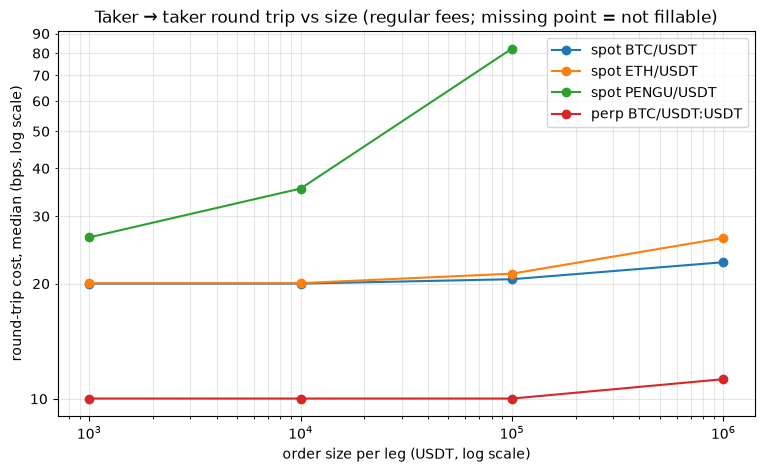

In [12]:
PLAIN = FuncFormatter(lambda v, _: f"{v:g}")   # 20 instead of 2×10^1 on log axes


def plot_lines(ax, summary, markets, combo, direction, style=None, label_suffix=""):
    for market in markets:
        s = summary.xs((market, combo, direction), level=("market", "combo", "direction"))
        ax.plot(s.index, s["median_bps"], marker="o", label=market + label_suffix,
                **(style or {}))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("order size per leg (USDT, log scale)")
    ax.set_ylabel("round-trip cost, median (bps, log scale)")
    ax.yaxis.set_major_formatter(PLAIN)
    ax.yaxis.set_minor_formatter(PLAIN)
    ax.grid(alpha=0.3, which="both")


fig, ax = plt.subplots(figsize=(9, 5))
plot_lines(ax, summary, MARKETS, "taker -> taker", "long")
ax.set_title("Taker → taker round trip vs size (regular fees; missing point = not fillable)")
ax.legend()
plt.show()

How to read it: x is the order size per leg in USDT, y the median round-trip cost in bps of the
notional; both axes are logarithmic (each grid step is ×10 on x). One line per market. A flat line
means the cost is a fixed share of the notional (fees + spread); a rising line means impact is
growing. A line that stops early has a size that the visible book could not fill. The gap between
the spot lines and the perp line at small sizes is the fee difference.

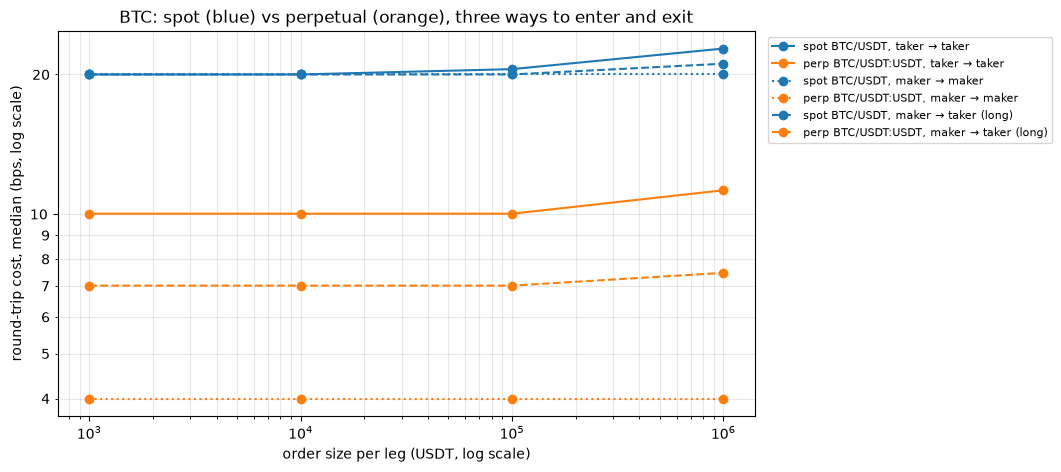

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
btc = ["spot BTC/USDT", "perp BTC/USDT:USDT"]
for (label, (combo, direction)), ls in zip(VIEWS.items(), ["-", ":", "--", "-."]):
    if direction == "short":
        continue
    for market, color in zip(btc, ["tab:blue", "tab:orange"]):
        s = summary.xs((market, combo, direction), level=("market", "combo", "direction"))
        ax.plot(s.index, s["median_bps"], ls=ls, color=color, marker="o", label=f"{market}, {label}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("order size per leg (USDT, log scale)")
ax.set_ylabel("round-trip cost, median (bps, log scale)")
ax.yaxis.set_major_formatter(PLAIN)
ax.yaxis.set_minor_formatter(PLAIN)
ax.grid(alpha=0.3, which="both")
ax.set_title("BTC: spot (blue) vs perpetual (orange), three ways to enter and exit")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

How to read it: same axes as the previous plot, only BTC. Color = product (blue spot, orange
perpetual), line style = combo (solid taker → taker, dotted maker → maker, dashed maker → taker
long). For each combo, the vertical gap between blue and orange is the spot − perp difference of
section 8; lines that stay flat across sizes are dominated by fees.

## Limitations

- **One window.** 45 minutes at one hour of one weekday, collected with the collector's old
  catch-up behavior (assumption 9). Costs at other hours, on weekends or in a crash can be much
  higher: books thin out exactly when one most wants to exit.
- **Lower bound on impact** (assumption 1): no latency, no cancellations, no hidden orders, no
  queue, and depth near the mid changes a lot every 10 s (notebook 06, section 9).
- **Maker numbers are "if filled".** No fill probability, no adverse selection, no queue position
  (assumption 6). A maker → maker round trip of 1M USDT assumes someone takes both limit orders
  in full, which is far from guaranteed.
- **The maker's half-spread gain is ignored** (assumption 5): maker legs are slightly
  overstated, by half a spread (negligible for BTC and ETH, not for PENGU).
- **Fees are inputs from secondary sources** (spot) for a regular user; VIP tiers, BNB, and
  promotions change them. Taxes and withdrawal/transfer costs are not included.
- **No funding** on the perpetual (assumption 8), and no margin interest for a short on spot
  (a spot short needs a borrow, which has its own cost).
- **The "truncated by the API" case** is handled by the code but did not occur in this window at
  these sizes (section 5); with larger sizes or thinner moments it would.

## Conclusions (key takeaways)

One window: Binance, Thursday 2026-11-19, 22:00–22:45 UTC (16:00–16:45 Mexico City), 270
snapshots per market. Impact is a lower bound, maker legs assume a fill, no funding. Nothing here
generalizes beyond that window.

1. **For BTC and ETH, the round trip is almost all fee up to 100k USDT: this part of the
   hypothesis holds, and the spread is negligible.** Taker → taker at 100k: fee share **97.4%**
   (BTC spot), **94.2%** (ETH spot), **99.8%** (BTC perp). The largest spread share in any combo
   and size is **0.008%** for BTC spot, **0.16%** for the perp and **0.28%** for ETH (section 9):
   the spread is one tick, a few thousandths of a bp (BTC spot) to a few hundredths (ETH, perp).
2. **At 1M USDT, impact grows but fees still dominate the liquid books: the "1M → impact is the
   main cost" part of the hypothesis is rejected for BTC and ETH.** Median taker → taker at 1M:
   **22.75 bps** BTC spot (impact 12.1% of it), **26.32 bps** ETH (23.8%), **11.25 bps** BTC perp
   (11.0%).
3. **PENGU is where the book matters.** Taker → taker rises from **26.42 bps** at 1k to
   **82.27 bps** at 100k, where impact is **73.0%** of the cost. A 1M sell was **not fillable in
   270/270 snapshots** ("book exhausted": the whole visible bid side held less than 1M USDT in
   every snapshot, minimum **0.41M**), so no 1M round trip with a market exit on the bids is reported; a 1M
   market buy (the exit of a short) cost a median **2,290.9 bps** round trip, about 23% of the
   notional. The "truncated by the API" case did not occur in any of the 8,640 legs.
4. **BTC on the perpetual costs about half as much as BTC spot, almost all through fees.** Median
   taker → taker: **10.02 vs 20.00 bps** at 1k–10k, **11.25 vs 22.75 bps** at 1M (**1,125 vs
   2,275 USDT**). Maker → maker: **4 vs 20 bps**. Paying spot fees in BNB lowers spot taker →
   taker to **15.0 bps** at 1k, still above the perp's 10.02. Funding (M8) is the perp's cost that
   is missing here.
5. **A limit entry saves little on spot and a lot on the perp, at a regular fee level.** On spot the
   maker and taker fees are equal, so maker → taker only saves the entry's half spread and
   impact: **20.00 vs 20.00 bps** for BTC at 10k, **21.10 vs 22.75** at 1M (long). On the perp the
   lower maker fee cuts the cost from **10.02 to 7.01 bps** at 10k, before the unmeasured risk of
   not being filled or of being filled just before an adverse move.